In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Linear Regression Model
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
# Train Test Package
from sklearn.model_selection import train_test_split, KFold, cross_val_score
# Feature Scaling
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
# Pipeline
from sklearn.pipeline import Pipeline
# Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv('Dataset/Real estate.csv')
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [3]:
df.isnull().sum()

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

In [4]:
df.columns

Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='object')

<Axes: ylabel='X6 longitude'>

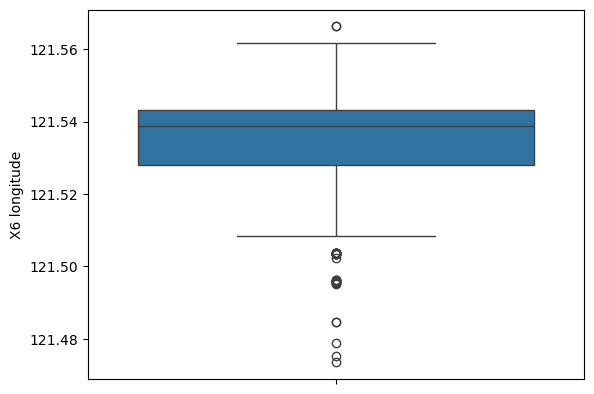

In [5]:
sns.boxplot(df['X6 longitude'])

In [6]:
df = df.drop(columns=['No', 'X1 transaction date'])

In [7]:
# df_corr = df.corr(method='spearman')
df_corr = df.corr(method='pearson')

In [21]:
plt.figure(figsize=(10, 4))
sns.heatmap(df_corr, annot=True)
plt.close()

## Feature and Target

In [9]:
features = ['X2 house age', 'X3 distance to the nearest MRT station', 'X4 number of convenience stores', 
            'X5 latitude', 'X6 longitude']
target = 'Y house price of unit area'

In [10]:
X = df[features]
Y = df[target]

## Train Test Split

In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

## Feature Scaling

In [ ]:
'''
scaler.fit_transform(X_train)
    -> fit_transform(training data)
        -> fit -> Learning -> Calculates mean and sd
        -> transform -> Implement -> Implements mean and sd into formula ((Xi - mean)/sd)

scaler.transform(X_test)
    -> transform(testing data)
        -> transform -> implement -> ((Xi - mean)/sd)
'''

In [12]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

## Model Implementation

In [13]:
model = LinearRegression()

In [ ]:
'''
- X_train -> Question
- Y_train -> Answer

- X_test -> Exam Question

- fit(training data) -> X_train, Y_Train -> Model Learning Phase
- predict(testing data) -> X_test
'''

In [14]:
model.fit(X_train_scale, Y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [15]:
Y_pred = model.predict(X_test_scale)

In [16]:
beta_0 = model.intercept_
beta_1 = model.coef_

print(f'Intercept: {beta_0}')
print(f'Slope / Coefficient: {beta_1}')

Intercept: 38.39154078549814
Slope / Coefficient: [-3.06045213 -5.53623761  3.25926406  2.94298597 -0.35743672]


## Adjusting R2 Score

In [29]:
def adjust_r2_score(r2, n, p):
    return 1 - ((1 - r2) * (n - 1)) / (n - p - 1)

In [28]:
n_sample = X_test_scale.shape[0]
p_data = X_train_scale.shape[1]

## Metrics

In [30]:
mae = mean_absolute_error(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(Y_test, Y_pred)
adjust_r2 = adjust_r2_score(r2, n_sample, p_data)

In [31]:
print(f'Mean Absolute Error: {mae}')
print(f'Mean Squared Error: {mse}')
print(f'Root Mean Squared Error: {rmse}')
print(f'R2 Score: {r2}')
print(f'Adjusted R2 Score: {adjust_r2}')

Mean Absolute Error: 5.350138374356212
Mean Squared Error: 54.580945200862146
Root Mean Squared Error: 7.3878917967754605
R2 Score: 0.6746481382828176
Adjusted R2 Score: 0.653521394015468


## Visualization

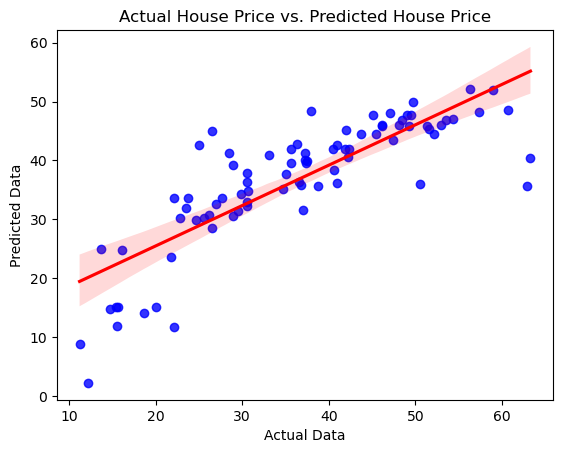

In [19]:
sns.regplot(x=Y_test, y=Y_pred, color='blue', line_kws={'color': 'red'})
plt.xlabel('Actual Data')
plt.ylabel('Predicted Data')
plt.title('Actual House Price vs. Predicted House Price')
plt.show()

In [ ]:
'''
Regression Model Regularization
-----------------------------------
1. Cross Validation
    -> If our dataset is small to medium sized. (0 to 40000)
    -> Make model learn multiple patterns of same data
    
2. Polynomial Regression
    -> If our data contains any non-linear features and has outliers.
    
3. Ridge Regression (L1)
    -> Converts high weight data number to near zero. To reduce biasness and handle outliers
    
4. Lasso Regression (L2)
    -> Removes high weight data.
    
5. Elastic Net Regression
    -> Combination of Ridge and Lasso Regression.
    
6. Adjusting Cost Function / R2 Score
    Formula
    ----------
    1 - ((1 - r2) * (n - 1)) / (n - p - 1)

    r2 -> R2 Score
    n -> Sample (Test Data Sample)
    p -> Population (Train Data Population)
'''

## Cross Validation

In [33]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
cv_score = cross_val_score(model, scaler.fit_transform(X), Y, scoring='r2')

print(f'Cross Validation Scores: {cv_score}')
print(f'Average Cross Validation Score: {cv_score.mean()}')

Cross Validation Scores: [0.68463546 0.53209757 0.66649314 0.42112676 0.57912236]
Average Cross Validation Score: 0.5766950593066446


## Polynomial Regression

In [37]:
poly_features = Pipeline([
    ('scaler', StandardScaler()),
    # degree=2 -> To find non-linear patterns
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear', LinearRegression())
])

In [40]:
poly_features.fit(X_train_scale, Y_train)
poly_pred = poly_features.predict(X_test_scale)
poly_r2 = r2_score(Y_test, poly_pred)
adjust_poly_r2 = adjust_r2_score(poly_r2, n_sample, p_data)

print(f'Polynomial R2 Score: {poly_r2}')
print(f'Adjusted Polynomial R2 Score: {adjust_poly_r2}')

Polynomial R2 Score: 0.7505332250103934
Adjusted Polynomial R2 Score: 0.7343340837773021


## Ridge Regression

In [43]:
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=0.1))
])
ridge_pipeline.fit(X_train_scale, Y_train)
ridge_pred = ridge_pipeline.predict(X_test_scale)
ridge_r2 = r2_score(Y_test, ridge_pred)
adjust_ridge_r2 = adjust_r2_score(ridge_r2, n_sample, p_data)

print(f'Ridge Regression R2 Score: {ridge_r2}')
print(f'Adjusted Ridge Regression R2 Score: {adjust_ridge_r2}')

Ridge Regression R2 Score: 0.6746757475106016
Adjusted Ridge Regression R2 Score: 0.653550796050251


## Lasso Regression

In [44]:
lasso_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.1))
])
lasso_pipeline.fit(X_train_scale, Y_train)
lasso_pred = lasso_pipeline.predict(X_test_scale)
lasso_r2 = r2_score(Y_test, lasso_pred)
adjust_lasso_r2 = adjust_r2_score(lasso_r2, n_sample, p_data)

print(f'Lasso Regression R2 Score: {lasso_r2}')
print(f'Adjusted Lasso Regression R2 Score: {adjust_lasso_r2}')

Lasso Regression R2 Score: 0.6761322962813272
Adjusted Lasso Regression R2 Score: 0.6551019259099848


## Elastic Net

In [45]:
elastic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('elastic', ElasticNet(alpha=0.1, l1_ratio=0.5))
])
elastic_pipeline.fit(X_train_scale, Y_train)
elastic_pred = lasso_pipeline.predict(X_test_scale)
elastic_r2 = r2_score(Y_test, elastic_pred)
adjust_elastic_r2 = adjust_r2_score(elastic_r2, n_sample, p_data)

print(f'Lasso Regression R2 Score: {elastic_r2}')
print(f'Adjusted Lasso Regression R2 Score: {adjust_elastic_r2}')

Lasso Regression R2 Score: 0.6761322962813272
Adjusted Lasso Regression R2 Score: 0.6551019259099848


## Visualization

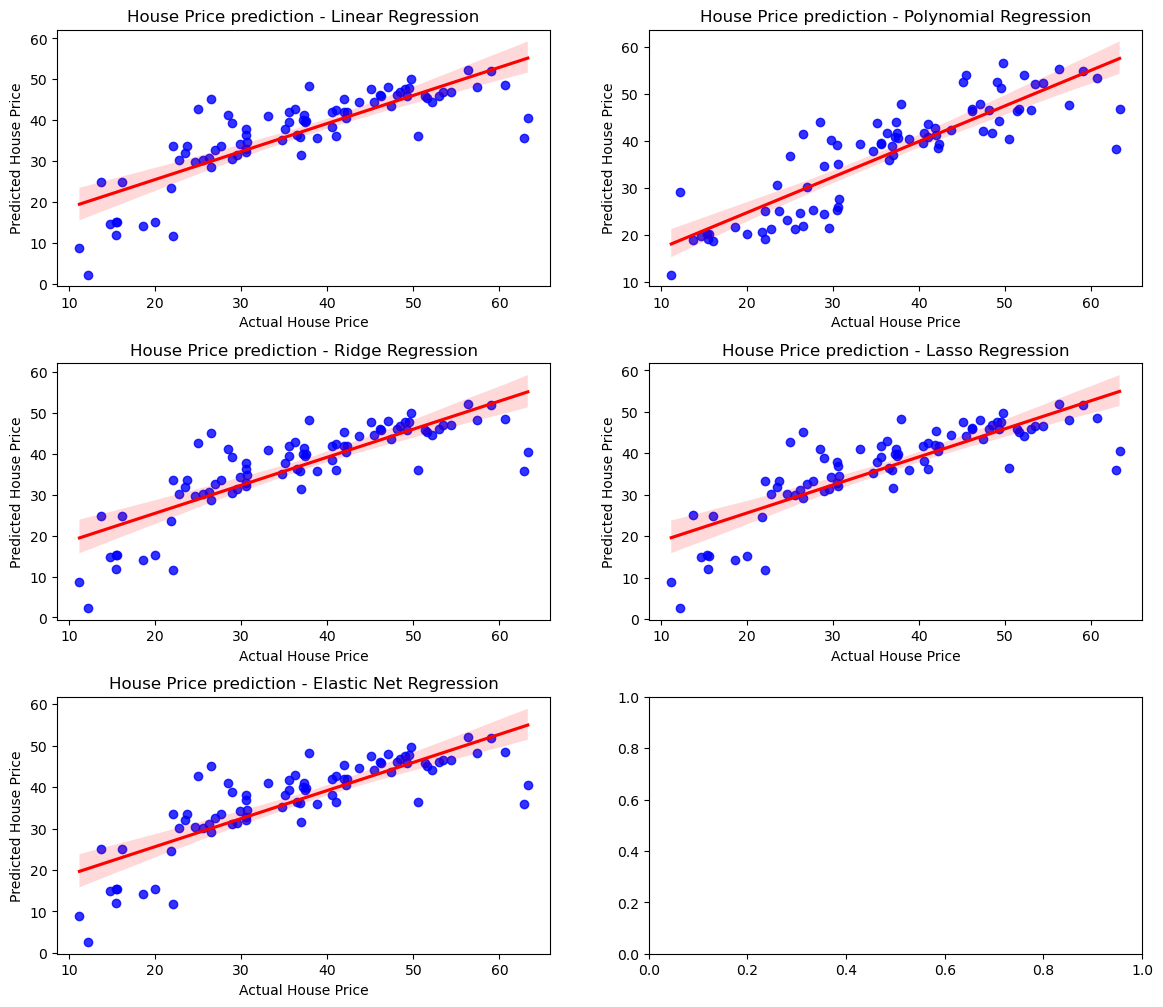

In [62]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
plt.subplots_adjust(hspace=0.3)

ax1 = axes[0, 0]
sns.regplot(x=Y_test, y=Y_pred, ax=ax1, color='blue', line_kws={'color': 'red'})
ax1.set_title('House Price prediction - Linear Regression')
ax1.set_xlabel('Actual House Price')
ax1.set_ylabel('Predicted House Price')

ax2 = axes[0, 1]
sns.regplot(x=Y_test, y=poly_pred, ax=ax2, color='blue', line_kws={'color': 'red'})
ax2.set_title('House Price prediction - Polynomial Regression')
ax2.set_xlabel('Actual House Price')
ax2.set_ylabel('Predicted House Price')

ax3 = axes[1, 0]
sns.regplot(x=Y_test, y=ridge_pred, ax=ax3, color='blue', line_kws={'color': 'red'})
ax3.set_title('House Price prediction - Ridge Regression')
ax3.set_xlabel('Actual House Price')
ax3.set_ylabel('Predicted House Price')

ax4 = axes[1, 1]
sns.regplot(x=Y_test, y=lasso_pred, ax=ax4, color='blue', line_kws={'color': 'red'})
ax4.set_title('House Price prediction - Lasso Regression')
ax4.set_xlabel('Actual House Price')
ax4.set_ylabel('Predicted House Price')

ax5 = axes[2, 0]
sns.regplot(x=Y_test, y=elastic_pred, ax=ax5, color='blue', line_kws={'color': 'red'})
ax5.set_title('House Price prediction - Elastic Net Regression')
ax5.set_xlabel('Actual House Price')
ax5.set_ylabel('Predicted House Price')

plt.show()